# Metric Stat Analysis – PPP Radar Evaluation

Loads pre-exported HDF5 evaluation files (`rank00.h5` – `rank03.h5`) produced by
the metric evaluation pipeline and provides first-look visualisation of
`img`, `pred_lambda`, and `gt_support` per sample.

Each h5 file organises samples as:
```
sample_XXXXXX/
    img          (H, W, 3)  uint8
    pred_lambda  (H, W)     float32
    gt_support   (H, W)     float32
```

## 1 · Import Required Libraries

In [35]:
import os
import glob
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import binary_dilation

plt.rcParams["figure.figsize"] = (18, 5)
plt.rcParams["image.cmap"] = "hot"

## 2 · Configuration & Path Setup

In [36]:

# ---------------------------------------------------------------------------
# Paths – one entry per model run
# ---------------------------------------------------------------------------

H5_DIRS = {
    "test_gen_data_meric_13600264": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test"
    ),
    "test_gen_data_meric_1500_13603608_LR_load_model40000": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_1500_13603608/20260327_012815/metric_eval_data/test"
    ),
    "test_gen_data_meric_1500_13606074": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_1500_13606074/20260327_133317/metric_eval_data/test"
    ),
}


# Select which model to analyse for the browser / per-sample cells
# ACTIVE_MODEL = "test_gen_data_meric_13600264"
ACTIVE_MODEL = "test_gen_data_meric_13600264"

H5_DIR = H5_DIRS[ACTIVE_MODEL]
assert os.path.isdir(H5_DIR), f"H5 directory not found: {H5_DIR}"

# ---------------------------------------------------------------------------
# Display parameters
# ---------------------------------------------------------------------------

# Radius (pixels) used to dilate each GT point for visibility.
# Increase to make GT dots larger in the output image.
GT_DILATION_RADIUS = 1

# ---------------------------------------------------------------------------
# Collect h5 files for the active model (browser / per-sample cells)
# ---------------------------------------------------------------------------

h5_files = sorted(glob.glob(os.path.join(H5_DIR, "rank*.h5")))

print(f"Active model : {ACTIVE_MODEL}")
print(f"H5_DIR       : {H5_DIR}")
print(f"\nFound {len(h5_files)} h5 file(s):")
for p in h5_files:
    print(" ", p)

print(f"\nAll models registered: {list(H5_DIRS.keys())}")
print(f"GT_DILATION_RADIUS = {GT_DILATION_RADIUS}  (display only)")


Active model : test_gen_data_meric_13600264
H5_DIR       : /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test

Found 4 h5 file(s):
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank00.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank01.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank02.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank03.h5

All models registered: ['test_gen_data_meric_13600264', 'test_gen_data_meric_1500_13603608_LR_load_model40000', 'test_gen_data_meric_1500_13606074']
GT_DILATION_RADIUS = 1  (display only)


## 3 · H5 Helper – List & Load Samples

In [37]:
def list_h5_samples(h5_paths):
    """
    Return a list of (h5_path, sample_key) tuples across all rank files,
    sorted globally by sample key.
    """
    entries = []
    for path in h5_paths:
        with h5py.File(path, "r") as f:
            for key in sorted(f.keys()):
                entries.append((path, key))
    return entries


def load_h5_sample(h5_path, sample_key):
    """
    Load one sample from an h5 file.

    Returns a dict with:
      img          – (H, W, 3) uint8
      pred_lambda  – (H, W) float32   [lambda(x), i.e. predicted intensity]
      gt_support   – (H, W) float32   [binary point support {0,1}]
      ppp          – derived diagnostics dict
    """
    with h5py.File(h5_path, "r") as f:
        grp = f[sample_key]
        img         = grp["img"][:]           # (H, W, 3) uint8
        pred_lambda = grp["pred_lambda"][:]   # (H, W)    float32
        gt_support  = grp["gt_support"][:]    # (H, W)    float32

    H, W = pred_lambda.shape
    expected_count = float(pred_lambda.sum())
    gt_count       = int(gt_support.sum())

    return {
        "img":         img,
        "pred_lambda": pred_lambda,
        "gt_support":  gt_support,
        "ppp": {
            "H":              H,
            "W":              W,
            "img_area":       H * W,
            "expected_count": expected_count,
            "gt_count":       gt_count,
            "count_error":    expected_count - gt_count,
        },
        "meta": {
            "h5_file":    os.path.basename(h5_path),
            "sample_key": sample_key,
        },
    }


# Build global sample index
all_samples = list_h5_samples(h5_files)
print(f"Total samples across all rank files: {len(all_samples)}")
print("First 5 entries:")
for entry in all_samples[:5]:
    print(f"  {os.path.basename(entry[0])} / {entry[1]}")

Total samples across all rank files: 500
First 5 entries:
  rank00.h5 / sample_000000
  rank00.h5 / sample_000001
  rank00.h5 / sample_000002
  rank00.h5 / sample_000003
  rank00.h5 / sample_000004


## 4 · PPP Sampling Methods

In [38]:
def sample_ppp_by_thinning(
    lambda_grid: np.ndarray,
    *,
    pixel_area: float | None = None,
    rng: np.random.Generator | None = None,
):
    """
    Sample an inhomogeneous PPP using thinning from a homogeneous PPP.

    Parameters
    ----------
    lambda_grid : (H, W) array
        Intensity lambda(x) per pixel (mass per pixel, non-negative).
    pixel_area : float
        Kept for API compatibility, not used.
    rng : np.random.Generator

    Returns
    -------
    points_xy  : (N, 2) array  – accepted points in image coords (x, y)
    N          : int
    lambda_max : float
    N_prop     : int           – number of proposals before thinning
    """
    if rng is None:
        rng = np.random.default_rng()

    lam = np.asarray(lambda_grid, dtype=np.float64)
    assert np.all(lam >= 0)
    H, W = lam.shape

    lambda_max = lam.max()
    if lambda_max == 0:
        return np.zeros((0, 2)), 0, 0.0, 0

    area_total = H * W
    Lambda_hom = lambda_max * area_total
    N_prop = rng.poisson(Lambda_hom)

    if N_prop == 0:
        return np.zeros((0, 2)), 0, lambda_max, 0

    xs = rng.random(N_prop) * W
    ys = rng.random(N_prop) * H
    xi = np.clip(xs.astype(int), 0, W - 1)
    yi = np.clip(ys.astype(int), 0, H - 1)

    lam_x = lam[yi, xi]
    accept_prob = lam_x / lambda_max
    keep = rng.random(N_prop) < accept_prob

    points_xy = np.stack([xs[keep], ys[keep]], axis=1)
    return points_xy, points_xy.shape[0], float(lambda_max), N_prop


def sample_points_block_bernoulli(
    lambda_grid: np.ndarray,
    *,
    block_size: int = 8,
    pixel_area: float = 1.0,
    placement: str = "weighted",
    rng: np.random.Generator | None = None,
):
    """
    Block/Bernoulli approximation of a PPP.

    For each block A:
        Λ_A = sum_A λ * pixel_area
        Activate with p_A = 1 - exp(-Λ_A)
    If active, place exactly one point in A.

    Parameters
    ----------
    lambda_grid : (H, W) array  – intensity mass per pixel
    block_size  : int           – side length of each block in pixels
    pixel_area  : float         – set to 1.0 when lambda_grid is already mass per pixel
    placement   : "weighted" | "uniform"

    Returns
    -------
    points_xy : (N, 2) array
    stats     : dict
    """
    if rng is None:
        rng = np.random.default_rng()

    lam = np.asarray(lambda_grid, dtype=np.float64)
    if lam.ndim != 2:
        raise ValueError("lambda_grid must be 2D.")
    if not np.all(np.isfinite(lam)):
        raise ValueError("lambda_grid contains NaN/Inf.")
    if np.any(lam < 0):
        raise ValueError("lambda_grid contains negative values.")
    if placement not in {"weighted", "uniform"}:
        raise ValueError("placement must be 'weighted' or 'uniform'")

    bs = int(block_size)
    H, W = lam.shape
    nby = (H + bs - 1) // bs
    nbx = (W + bs - 1) // bs
    num_blocks = nby * nbx

    Hp, Wp = nby * bs, nbx * bs
    if Hp != H or Wp != W:
        lam_pad = np.zeros((Hp, Wp), dtype=np.float64)
        lam_pad[:H, :W] = lam
    else:
        lam_pad = lam

    lam_blocks = lam_pad.reshape(nby, bs, nbx, bs).transpose(0, 2, 1, 3)
    block_sums = lam_blocks.sum(axis=(2, 3)) * pixel_area  # (nby, nbx)

    p_active = 1.0 - np.exp(-block_sums)
    expected_blocks_active = float(p_active.sum())

    active_mask = rng.random(size=(nby, nbx)) < p_active
    active_by, active_bx = np.nonzero(active_mask)
    num_active = active_by.size

    if num_active == 0:
        return np.zeros((0, 2), dtype=np.float64), dict(
            block_size=bs, placement=placement,
            num_blocks=num_blocks, num_active_blocks=0,
            expected_active_blocks=expected_blocks_active, num_points=0,
        )

    points_xy = np.empty((num_active, 2), dtype=np.float64)
    x0s = active_bx * bs
    y0s = active_by * bs
    wBs = np.minimum(bs, W - x0s)
    hBs = np.minimum(bs, H - y0s)

    if placement == "uniform":
        points_xy[:, 0] = x0s + rng.random(num_active) * wBs
        points_xy[:, 1] = y0s + rng.random(num_active) * hBs
    else:
        for i, (by, bx, x0, y0, wB, hB) in enumerate(
            zip(active_by, active_bx, x0s, y0s, wBs, hBs)
        ):
            block = lam[y0:y0 + hB, x0:x0 + wB]
            s = block.sum()
            if s <= 0:
                points_xy[i, 0] = x0 + rng.random() * wB
                points_xy[i, 1] = y0 + rng.random() * hB
                continue
            probs = block.ravel() / s
            idx = rng.choice(probs.size, p=probs)
            py, px = divmod(idx, wB)
            points_xy[i, 0] = x0 + px + rng.random()
            points_xy[i, 1] = y0 + py + rng.random()

    return points_xy, dict(
        block_size=bs, placement=placement,
        num_blocks=num_blocks, num_active_blocks=int(num_active),
        expected_active_blocks=expected_blocks_active, num_points=int(num_active),
    )

print("Sampling functions loaded: sample_ppp_by_thinning, sample_points_block_bernoulli")


Sampling functions loaded: sample_ppp_by_thinning, sample_points_block_bernoulli


## 4 · Load & Display First Sample: Image, Lambda, GT

Sample : rank00.h5  /  sample_000000
Shape  : img=(544, 1792, 3)  pred_lambda=(544, 1792) _gt_support=(544, 1792)
PPP    : E[N]=106.85  GT=67  err=+39.85


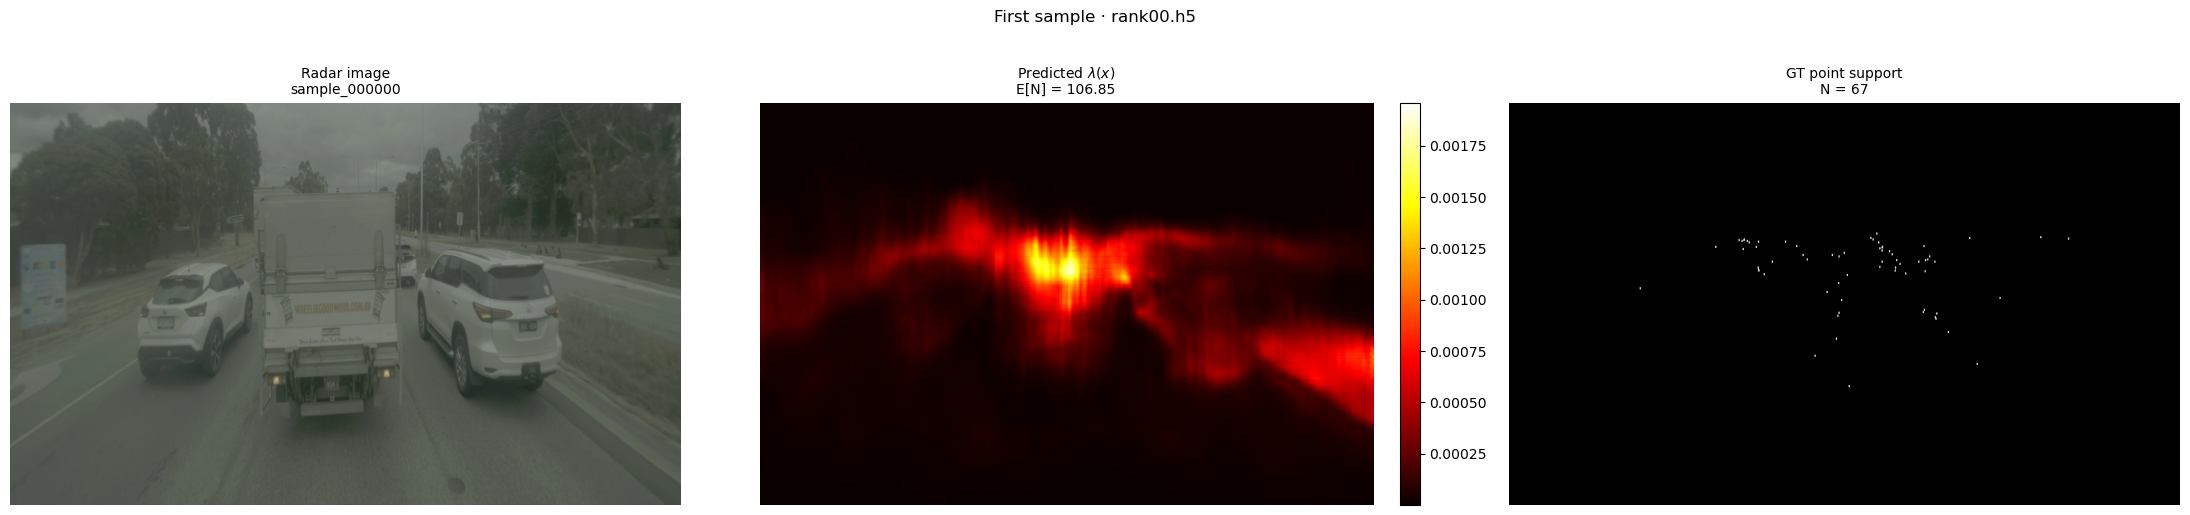

In [39]:
# Load first sample
h5_path_0, key_0 = all_samples[0]
sample = load_h5_sample(h5_path_0, key_0)

img         = sample["img"]
pred_lambda = sample["pred_lambda"]
gt_support  = sample["gt_support"]   # original – untouched
ppp         = sample["ppp"]
meta        = sample["meta"]

print(f"Sample : {meta['h5_file']}  /  {meta['sample_key']}")
print(f"Shape  : img={img.shape}  pred_lambda={pred_lambda.shape} _gt_support={gt_support.shape}")
print(f"PPP    : E[N]={ppp['expected_count']:.2f}  GT={ppp['gt_count']}  err={ppp['count_error']:+.2f}")

# GT point coordinates (row=y, col=x)
gt_ys, gt_xs = np.where(gt_support > 0)

# --- Side-by-side plot ---
fig, axes = plt.subplots(1, 3, figsize=(22, 5))

ax = axes[0]
ax.imshow(img, aspect="auto")
ax.set_title(f"Radar image\n{meta['sample_key']}", fontsize=10)
ax.axis("off")

ax = axes[1]
im = ax.imshow(pred_lambda, cmap="hot", aspect="auto")
ax.set_title(
    r"Predicted $\lambda(x)$"
    f"\nE[N] = {ppp['expected_count']:.2f}",
    fontsize=10,
)
ax.axis("off")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

ax = axes[2]
_struct = np.ones((2 * GT_DILATION_RADIUS + 1, 2 * GT_DILATION_RADIUS + 1), dtype=bool)
_gt_vis = binary_dilation(gt_support > 0, structure=_struct)
gt_rgb = np.zeros((*gt_support.shape, 3), dtype=np.uint8)
gt_rgb[_gt_vis] = 255
ax.imshow(gt_rgb, aspect="auto")
ax.set_title(
    f"GT point support\nN = {ppp['gt_count']}",
    fontsize=10,
)
ax.axis("off")

plt.suptitle(f"First sample · {meta['h5_file']}", fontsize=12, y=1.02)


plt.tight_layout()
plt.show()

In [40]:
# Pick 10 random samples from all_samples and report pred_lambda stats
assert len(all_samples) > 0, "all_samples is empty."

rng = np.random.default_rng(42)
k = min(10, len(all_samples))
picked_idx = rng.choice(len(all_samples), size=k, replace=False)

heatmap_stats = []
for i in picked_idx:
    h5_path, sample_key = all_samples[i]
    s = load_h5_sample(h5_path, sample_key)
    lam = s["pred_lambda"].astype(np.float64)

    heatmap_stats.append({
        "h5_file": os.path.basename(h5_path),
        "sample_key": sample_key,
        "max": float(lam.max()),
        "min": float(lam.min()),
        "mean": float(lam.mean()),
        "variance": float(lam.var()),
    })

print(f"Randomly selected {k} sample(s):\n")
for row in heatmap_stats:
    print(
        f"{row['h5_file']} / {row['sample_key']}  "
        f"max={row['max']:.6f}  min={row['min']:.6f}  "
        f"mean={row['mean']:.6f}  var={row['variance']:.6f}"
    )

Randomly selected 10 sample(s):

rank00.h5 / sample_000042  max=0.014833  min=0.000000  mean=0.000293  var=0.000001
rank03.h5 / sample_000005  max=0.041295  min=0.000000  mean=0.000203  var=0.000002
rank00.h5 / sample_000043  max=0.001602  min=0.000005  mean=0.000187  var=0.000000
rank02.h5 / sample_000072  max=0.004771  min=0.000005  mean=0.000232  var=0.000000
rank01.h5 / sample_000091  max=0.074664  min=0.000000  mean=0.000193  var=0.000002
rank01.h5 / sample_000089  max=0.090229  min=0.000000  mean=0.000224  var=0.000002
rank02.h5 / sample_000097  max=0.020466  min=0.000000  mean=0.000179  var=0.000001
rank00.h5 / sample_000047  max=0.001333  min=0.000003  mean=0.000127  var=0.000000
rank00.h5 / sample_000100  max=0.004594  min=0.000000  mean=0.000099  var=0.000000
rank03.h5 / sample_000050  max=0.024412  min=0.000000  mean=0.000302  var=0.000001


## 5 · Interactive Sample Browser

Use the slider to step through samples. Click **"Add to selection"** to mark the current sample. The selected keys are collected in `selected_samples` (printed in the cell below).

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# ── persistent selection list ────────────────────────────────────────────────
selected_samples = []   # list of (h5_file, sample_key)

# ── widgets ──────────────────────────────────────────────────────────────────
n = len(all_samples)

slider = widgets.IntSlider(
    value=0, min=0, max=n - 1, step=1,
    description="Sample:",
    continuous_update=False,
    layout=widgets.Layout(width="600px"),
)

btn_add = widgets.ToggleButton(
    value=False,
    description="☆  Add to selection",
    button_style="",
    layout=widgets.Layout(width="180px"),
)

lbl_status = widgets.Label(value=f"0 / {n} selected")

plot_out   = widgets.Output()
select_out = widgets.Output()


def _update_btn_label(idx):
    """Reflect whether the current sample is already in the selection."""
    h5_path, key = all_samples[idx]
    entry = (os.path.basename(h5_path), key)
    btn_add.value       = entry in selected_samples
    btn_add.description = "★  In selection" if btn_add.value else "☆  Add to selection"
    btn_add.button_style = "success" if btn_add.value else ""


def _render(idx):
    h5_path, key = all_samples[idx]
    sample = load_h5_sample(h5_path, key)

    img         = sample["img"]
    pred_lambda = sample["pred_lambda"]
    gt_support  = sample["gt_support"]
    ppp         = sample["ppp"]
    meta        = sample["meta"]

    gt_ys, gt_xs = np.where(gt_support > 0)

    with plot_out:
        clear_output(wait=True)
        fig, axes = plt.subplots(1, 3, figsize=(22, 5))

        axes[0].imshow(img, aspect="auto")
        axes[0].set_title(f"Radar image\n{meta['sample_key']}", fontsize=10)
        axes[0].axis("off")

        im = axes[1].imshow(pred_lambda, cmap="hot", aspect="auto")
        axes[1].set_title(
            r"Predicted $\lambda(x)$" + f"\nE[N] = {ppp['expected_count']:.2f}",
            fontsize=10,
        )
        axes[1].axis("off")
        plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

        _struct = np.ones((2 * GT_DILATION_RADIUS + 1, 2 * GT_DILATION_RADIUS + 1), dtype=bool)
        _gt_vis = binary_dilation(gt_support > 0, structure=_struct)
        _gt_rgb = np.zeros((*gt_support.shape, 3), dtype=np.uint8)
        _gt_rgb[_gt_vis] = 255
        axes[2].imshow(_gt_rgb, aspect="auto")
        axes[2].set_title(
            f"GT support\nN = {ppp['gt_count']}",
            fontsize=10,
        )
        axes[2].axis("off")

        plt.suptitle(
            f"[{idx + 1}/{n}]  {meta['h5_file']}  ·  {meta['sample_key']}"
            f"   |   E[N]={ppp['expected_count']:.2f}  GT={ppp['gt_count']}"
            f"  err={ppp['count_error']:+.2f}",
            fontsize=11, y=1.02,
        )
        plt.tight_layout()
        plt.show()


def _refresh_selection_output():
    with select_out:
        clear_output(wait=True)
        if selected_samples:
            print(f"Selected ({len(selected_samples)}):")
            for h5f, k in selected_samples:
                print(f"  {h5f}  /  {k}")
        else:
            print("No samples selected yet.")


def on_slider_change(change):
    _update_btn_label(change["new"])
    _render(change["new"])


def on_toggle_change(change):
    idx = slider.value
    h5_path, key = all_samples[idx]
    entry = (os.path.basename(h5_path), key)

    if change["new"]:                          # toggled ON → add
        if entry not in selected_samples:
            selected_samples.append(entry)
        btn_add.description  = "★  In selection"
        btn_add.button_style = "success"
    else:                                      # toggled OFF → remove
        if entry in selected_samples:
            selected_samples.remove(entry)
        btn_add.description  = "☆  Add to selection"
        btn_add.button_style = ""

    lbl_status.value = f"{len(selected_samples)} / {n} selected"
    _refresh_selection_output()


slider.observe(on_slider_change, names="value")
btn_add.observe(on_toggle_change, names="value")

# ── initial render ────────────────────────────────────────────────────────────
_update_btn_label(0)
_render(0)
_refresh_selection_output()

# ── layout ────────────────────────────────────────────────────────────────────
controls = widgets.HBox([slider, btn_add, lbl_status])

display(widgets.VBox([controls, plot_out, select_out]))
# ── layout ────────────────────────────────────────────────────────────────────controls = widgets.HBox([slider, btn_add, lbl_status])display(widgets.VBox([controls, plot_out, select_out]))


In [44]:
# ── Print final selection (run this cell after browsing) ─────────────────────
print(f"selected_samples = {selected_samples!r}")


selected_samples = [('rank00.h5', 'sample_000000'), ('rank00.h5', 'sample_000109')]


## Analysis: Per-sample evaluation — Gaussian-MMD

For every sample in `selected_samples`, produces a **3 × 3** figure:

| | Col 0 | Col 1 | Col 2 |
|---|---|---|---|
| **Row 0** | Image + real GT | $h_\text{pred}$ (norm. to $N_\text{GT}$) | $h_\text{GT}$ (pseudo-GT, Gaussian bumps) |
| **Row 1** | $\log h_\text{pred}$ @ real GT pixels | $\log h_\text{GT}$ @ real GT pixels (reference) | Score bar: real GT vs fake GT |
| **Row 2** | Image + fake GT (Gaussian cluster) | $h_\text{fake}$ (pseudo-fake heatmap) | $\log h_\text{pred}$ @ fake GT pixels |

The **fake GT** is a Gaussian cluster of the same $N$ points placed at a fixed off-centre location.  
A well-trained heatmap should give **MMD(real GT) >> MMD(fake GT)**.  
All log maps share a common colour scale for direct comparison.


In [45]:
# Max heatmap (pred_lambda) value across selected_samples
assert selected_samples, "selected_samples is empty."

global_max = -np.inf
global_arg = None

for h5_file, sample_key in selected_samples:
    h5_path = next(
        p for (p, k) in all_samples
        if os.path.basename(p) == h5_file and k == sample_key
    )
    s = load_h5_sample(h5_path, sample_key)
    m = float(np.max(s["pred_lambda"]))
    if m > global_max:
        global_max = m
        global_arg = (h5_file, sample_key)

print(f"Max heatmap value (pred_lambda): {global_max:.6f}")
print(f"Found in: {global_arg[0]} / {global_arg[1]}")

Max heatmap value (pred_lambda): 0.006954
Found in: rank00.h5 / sample_000109


  Heatmap Log-Likelihood – Synthetic Demo
  Grid: 64×64  |  GT points: 10

  Case                           score   score_rel
  ------------------------------------------------
  Aligned  (good)              -5.9667      2.3510
  Shifted  (bad)              -14.5901     -6.2724
  Uniform  (baseline)          -8.3178      0.0000

  Expected: score_aligned > score_uniform > score_shifted
            score_relative > 0 (aligned)  ≈ 0 (uniform)  < 0 (shifted)

  Batch summary (3 cases):
    mean score     : -9.6249  ±  3.6398
    mean score_rel : -1.3071  ±  3.6398


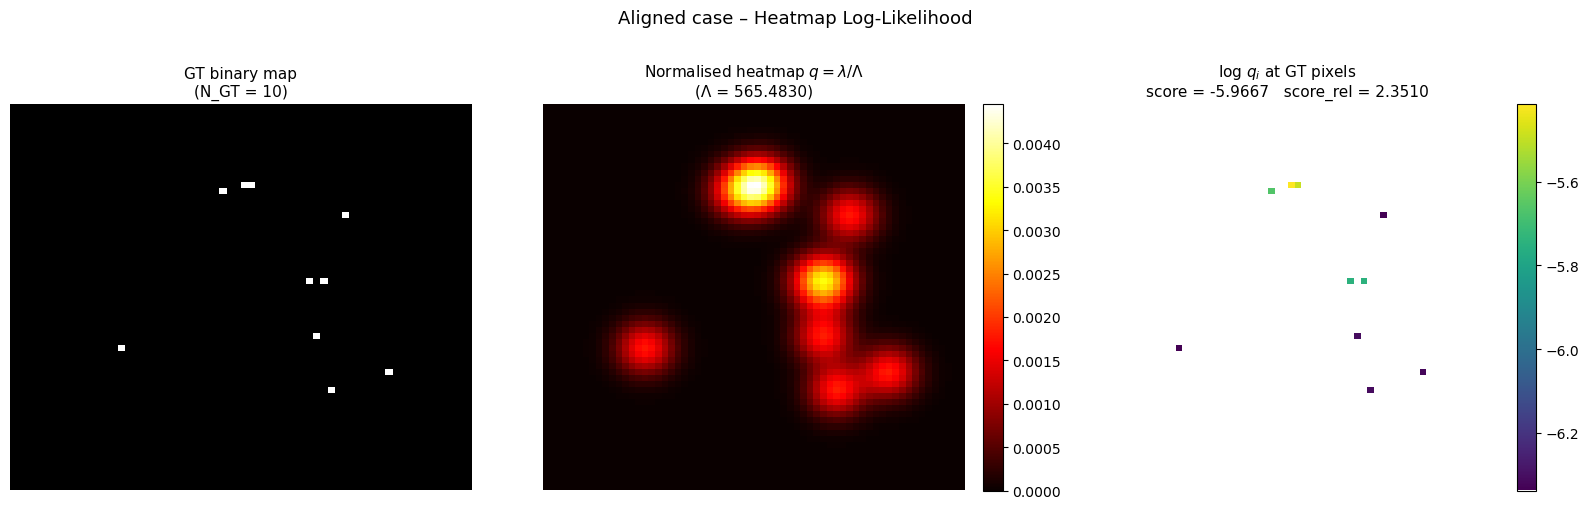


Loaded: heatmap_log_likelihood, batch_heatmap_log_likelihood, visualize_log_likelihood, demo_synthetic, points_to_binary_grid


In [ ]:

# ── Gaussian-MMD Heatmap Evaluation Module ────────────────────────────────────
#
# For each sample we have:
#   pred_lambda : (H, W) float32  – predicted intensity λ(x)  (sum = E[N])
#   gt_support  : (H, W) float32  – binary GT point support   (sum = N_GT)
#
# The metric compares predicted and GT "intensity distributions" in log-space,
# evaluated at the actual GT point locations.
#
#  ┌──────────────────────────────────────────────────────────────────────────┐
#  │  Pseudo-GT heatmap                                                        │
#  │    h_GT(x) = Σ_{j: x_j∈GT}  G_σ(x − x_j)   (Gaussian bump per GT point) │
#  │  Normalised so  Σ_x h_GT(x) = N_GT.                                       │
#  │  (In continuous space this is automatic for unit-norm Gaussians;           │
#  │   on a discrete grid we re-scale to account for boundary truncation.)      │
#  │                                                                            │
#  │  Normalised predicted heatmap                                              │
#  │    h_pred(x)  =  λ(x) · (N_GT / Λ),    Λ = Σ_x λ(x)                      │
#  │  so Σ_x h_pred = N_GT  (same scale as h_GT).                              │
#  │                                                                            │
#  │  Scores evaluated at actual GT locations x_i:                              │
#  │    score_pred   = (1/N_GT) Σ_{i∈GT} log h_pred(x_i)                       │
#  │    score_pseudo = (1/N_GT) Σ_{i∈GT} log h_GT(x_i)    ← reference         │
#  │                                                                            │
#  │  MMD score = score_pred − score_pseudo                                     │
#  │    0        → prediction matches the Gaussian-smoothed GT reference        │
#  │    negative → prediction places less mass at GT locations                  │
#  │    positive → prediction is more concentrated at GT locations than σ bumps │
#  └──────────────────────────────────────────────────────────────────────────┘
#
#  Bandwidth σ controls the sharpness of the GT reference bumps:
#    small σ → tight bumps (demanding reference, metric is very sensitive)
#    large σ → diffuse bumps (permissive reference, nearly uniform)
#  Set SIGMA_PX below to choose σ in pixels.

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from typing import Dict, List, Optional

EPS      = 1e-8    # log clamp
SIGMA_PX = 5.0     # ← Gaussian bandwidth for pseudo-GT bumps (pixels)


# ── 1. Pseudo-GT heatmap builder ─────────────────────────────────────────────

def build_pseudo_gt_heatmap(
    gt_support: np.ndarray,
    sigma: float = SIGMA_PX,
) -> np.ndarray:
    """
    Build the pseudo-GT heatmap by convolving the binary GT grid with a
    Gaussian kernel of bandwidth `sigma`, then rescaling so the total mass
    equals N_GT.

    Parameters
    ----------
    gt_support : (H, W) binary array   (values in {0, 1})
    sigma      : Gaussian bandwidth in pixels

    Returns
    -------
    h_GT : (H, W) float64   with  h_GT.sum() = N_GT  (up to fp precision)
            If N_GT = 0 or sigma ≤ 0, returns gt_support unchanged.
    """
    gt   = np.asarray(gt_support, dtype=np.float64)
    N_GT = float(gt.sum())

    if N_GT == 0.0 or sigma <= 0.0:
        return gt.copy()

    # Convolve: each GT-pixel contributes a Gaussian bump to the grid.
    # mode='constant', cval=0  →  zero-padding (truncates bumps at image edge).
    h = gaussian_filter(gt, sigma=sigma, mode="constant", cval=0.0)

    # Re-normalise so that Σ_x h(x) = N_GT regardless of boundary truncation.
    s = h.sum()
    if s > 0.0:
        h *= N_GT / s
    return h


# ── 2. Per-sample Gaussian-MMD score ────────────────────────────────────────

def gaussian_mmd_score(
    gt_support:  np.ndarray,
    pred_lambda: np.ndarray,
    sigma: float = SIGMA_PX,
    eps:   float = EPS,
) -> Dict[str, float]:
    """
    Gaussian-MMD score comparing the predicted heatmap to the pseudo-GT heatmap.

    Both heatmaps are normalised to integral = N_GT before the comparison.
    The score is evaluated at the actual GT pixel locations.

    Parameters
    ----------
    gt_support   : (H, W) binary {0, 1}
    pred_lambda  : (H, W) non-negative predicted intensity
    sigma        : Gaussian bandwidth for pseudo-GT bumps (pixels)
    eps          : clamp before log (numerical safety)

    Returns
    -------
    dict:
        mmd_score    – score_pred − score_pseudo  (higher = better; 0 = ideal)
        score_pred   – (1/N_GT) Σ_{GT} log h_pred(x_i)
        score_pseudo – (1/N_GT) Σ_{GT} log h_GT(x_i)   ← reference
        sigma        – bandwidth used
        N_GT         – number of GT points
        Lambda       – total predicted mass (Σ λ)
    """
    gt  = np.asarray(gt_support,  dtype=np.float64)
    lam = np.asarray(pred_lambda, dtype=np.float64)

    if gt.ndim != 2 or lam.ndim != 2:
        raise ValueError("Both arrays must be 2-D (H, W).")
    if gt.shape != lam.shape:
        raise ValueError(f"Shape mismatch: gt_support={gt.shape}, pred_lambda={lam.shape}")
    if np.any(lam < 0):
        raise ValueError("pred_lambda must be non-negative.")

    N_GT   = int(gt.sum())
    Lambda = float(lam.sum())

    if N_GT == 0:
        return dict(mmd_score=np.nan, score_pred=np.nan, score_pseudo=np.nan,
                    sigma=sigma, N_GT=0, Lambda=Lambda)
    if Lambda <= 0.0:
        raise ValueError("pred_lambda must have positive total mass.")

    # 1. Pseudo-GT heatmap: sum = N_GT
    h_GT = build_pseudo_gt_heatmap(gt, sigma=sigma)

    # 2. Normalise predicted heatmap to sum = N_GT
    h_pred = lam * (N_GT / Lambda)

    # 3. Evaluate at GT-pixel locations
    gt_flat   = gt.ravel() > 0.5
    log_pred  = np.log(np.clip(h_pred.ravel()[gt_flat], eps, None))
    log_pseudo = np.log(np.clip(h_GT.ravel()[gt_flat],  eps, None))

    score_pred   = float(log_pred.mean())
    score_pseudo = float(log_pseudo.mean())

    return dict(
        mmd_score    = score_pred - score_pseudo,
        score_pred   = score_pred,
        score_pseudo = score_pseudo,
        sigma        = sigma,
        N_GT         = N_GT,
        Lambda       = Lambda,
    )


# ── 3. Batch helper ──────────────────────────────────────────────────────────

def batch_gaussian_mmd(
    gt_list:  List[np.ndarray],
    lam_list: List[np.ndarray],
    sigma: float = SIGMA_PX,
    eps:   float = EPS,
) -> Dict:
    """
    Gaussian-MMD for a list of (GT, λ) pairs.

    Returns
    -------
    dict:
        per_sample       – list of per-sample metric dicts
        mean_mmd         – mean MMD score across samples
        std_mmd          – std  MMD score
        mean_score_pred  – mean predicted log score
        mean_score_pseudo– mean pseudo-GT reference log score
    """
    if len(gt_list) != len(lam_list):
        raise ValueError("gt_list and lam_list must have the same length.")
    per_sample = [gaussian_mmd_score(g, l, sigma=sigma, eps=eps)
                  for g, l in zip(gt_list, lam_list)]
    mmd    = np.array([d["mmd_score"]    for d in per_sample], dtype=float)
    sp     = np.array([d["score_pred"]   for d in per_sample], dtype=float)
    ss     = np.array([d["score_pseudo"] for d in per_sample], dtype=float)
    return dict(
        per_sample        = per_sample,
        mean_mmd          = float(np.nanmean(mmd)),
        std_mmd           = float(np.nanstd(mmd)),
        mean_score_pred   = float(np.nanmean(sp)),
        mean_score_pseudo = float(np.nanmean(ss)),
    )


# ── 4. Demo: three synthetic cases ───────────────────────────────────────────

def demo_gaussian_mmd(sigma: float = SIGMA_PX) -> None:
    """
    Compare three heatmaps that differ in how well they concentrate mass at
    the GT locations:

      Case 1 – Aligned: Gaussian blobs centred on GT points  (good)
      Case 2 – Shifted: same blobs displaced 15 px           (bad)
      Case 3 – Uniform: constant λ                            (flat baseline)

    Expected ordering of MMD score: aligned > uniform ≈ 0 > shifted.
    (The Gaussian pseudo-GT is accurate for aligned; both uniform and shifted
     will score lower because the GT self-reference naturally concentrates
     at GT locations.)
    """
    rng = np.random.default_rng(42)
    H, W = 64, 64

    n_pts = 10
    ys = rng.integers(10, H - 10, size=n_pts)
    xs = rng.integers(10, W - 10, size=n_pts)
    gt = np.zeros((H, W), dtype=np.float64)
    gt[ys, xs] = 1.0

    def _bumps(cx, cy, sh=3.0):
        yy, xx = np.mgrid[:H, :W]
        return sum(
            np.exp(-((yy - cy[k]) ** 2 + (xx - cx[k]) ** 2) / (2 * sh ** 2))
            for k in range(len(cx))
        )

    lam_aligned = _bumps(xs, ys)
    lam_shifted = _bumps(np.clip(xs + 15, 0, W - 1), ys)
    lam_uniform = np.ones((H, W), dtype=np.float64)

    pseudo_gt = build_pseudo_gt_heatmap(gt, sigma=sigma)

    print("=" * 72)
    print(f"  Gaussian-MMD Demo   (σ = {sigma} px)")
    print("=" * 72)
    print(f"  Grid {H}×{W}  |  GT points: {n_pts}  |  pseudo-GT sum = {pseudo_gt.sum():.2f}")
    print()
    print(f"  {'Case':<26}  {'score_pred':>11}  {'score_pseudo':>12}  {'mmd_score':>10}")
    print(f"  {'-'*63}")
    for name, lam in [
        ("Aligned  (good)", lam_aligned),
        ("Shifted  (bad)",  lam_shifted),
        ("Uniform  (flat)", lam_uniform),
    ]:
        m = gaussian_mmd_score(gt, lam, sigma=sigma)
        print(f"  {name:<26}  {m['score_pred']:>11.4f}  {m['score_pseudo']:>12.4f}  {m['mmd_score']:>10.4f}")
    print()
    print("  Expected: mmd_score  aligned >> uniform ≈ 0 > shifted")
    print("  (score_pseudo is the same for all cases – it depends only on GT)")
    print("=" * 72)

    # Plot pseudo-GT heatmap and log-values
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    axes[0].imshow(gt, cmap="gray", aspect="auto")
    axes[0].set_title(f"GT binary  (N={n_pts})", fontsize=11); axes[0].axis("off")
    im = axes[1].imshow(pseudo_gt, cmap="hot", aspect="auto")
    axes[1].set_title(f"Pseudo-GT heatmap  σ={sigma} px\nsum={pseudo_gt.sum():.1f}", fontsize=11)
    axes[1].axis("off"); plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
    h_pred_a = lam_aligned * (n_pts / lam_aligned.sum())
    log_map  = np.where(gt > 0.5, np.log(np.clip(h_pred_a, EPS, None)), np.nan)
    im2 = axes[2].imshow(log_map, cmap="viridis", aspect="auto")
    axes[2].set_title(f"log h_pred at GT pixels (aligned)\nmmd={gaussian_mmd_score(gt, lam_aligned, sigma)['mmd_score']:.4f}", fontsize=11)
    axes[2].axis("off"); plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)
    plt.suptitle("Gaussian-MMD – Synthetic Demo", fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()


demo_gaussian_mmd()

print(
    "\nLoaded: build_pseudo_gt_heatmap, gaussian_mmd_score, "
    "batch_gaussian_mmd, demo_gaussian_mmd"
)
print(f"Active bandwidth: SIGMA_PX = {SIGMA_PX} px  (edit at top of this cell)")


/tmp/ipykernel_23432/1276041259.py:130: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax_box.boxplot(_bp_data, labels=_bp_labels, patch_artist=True,


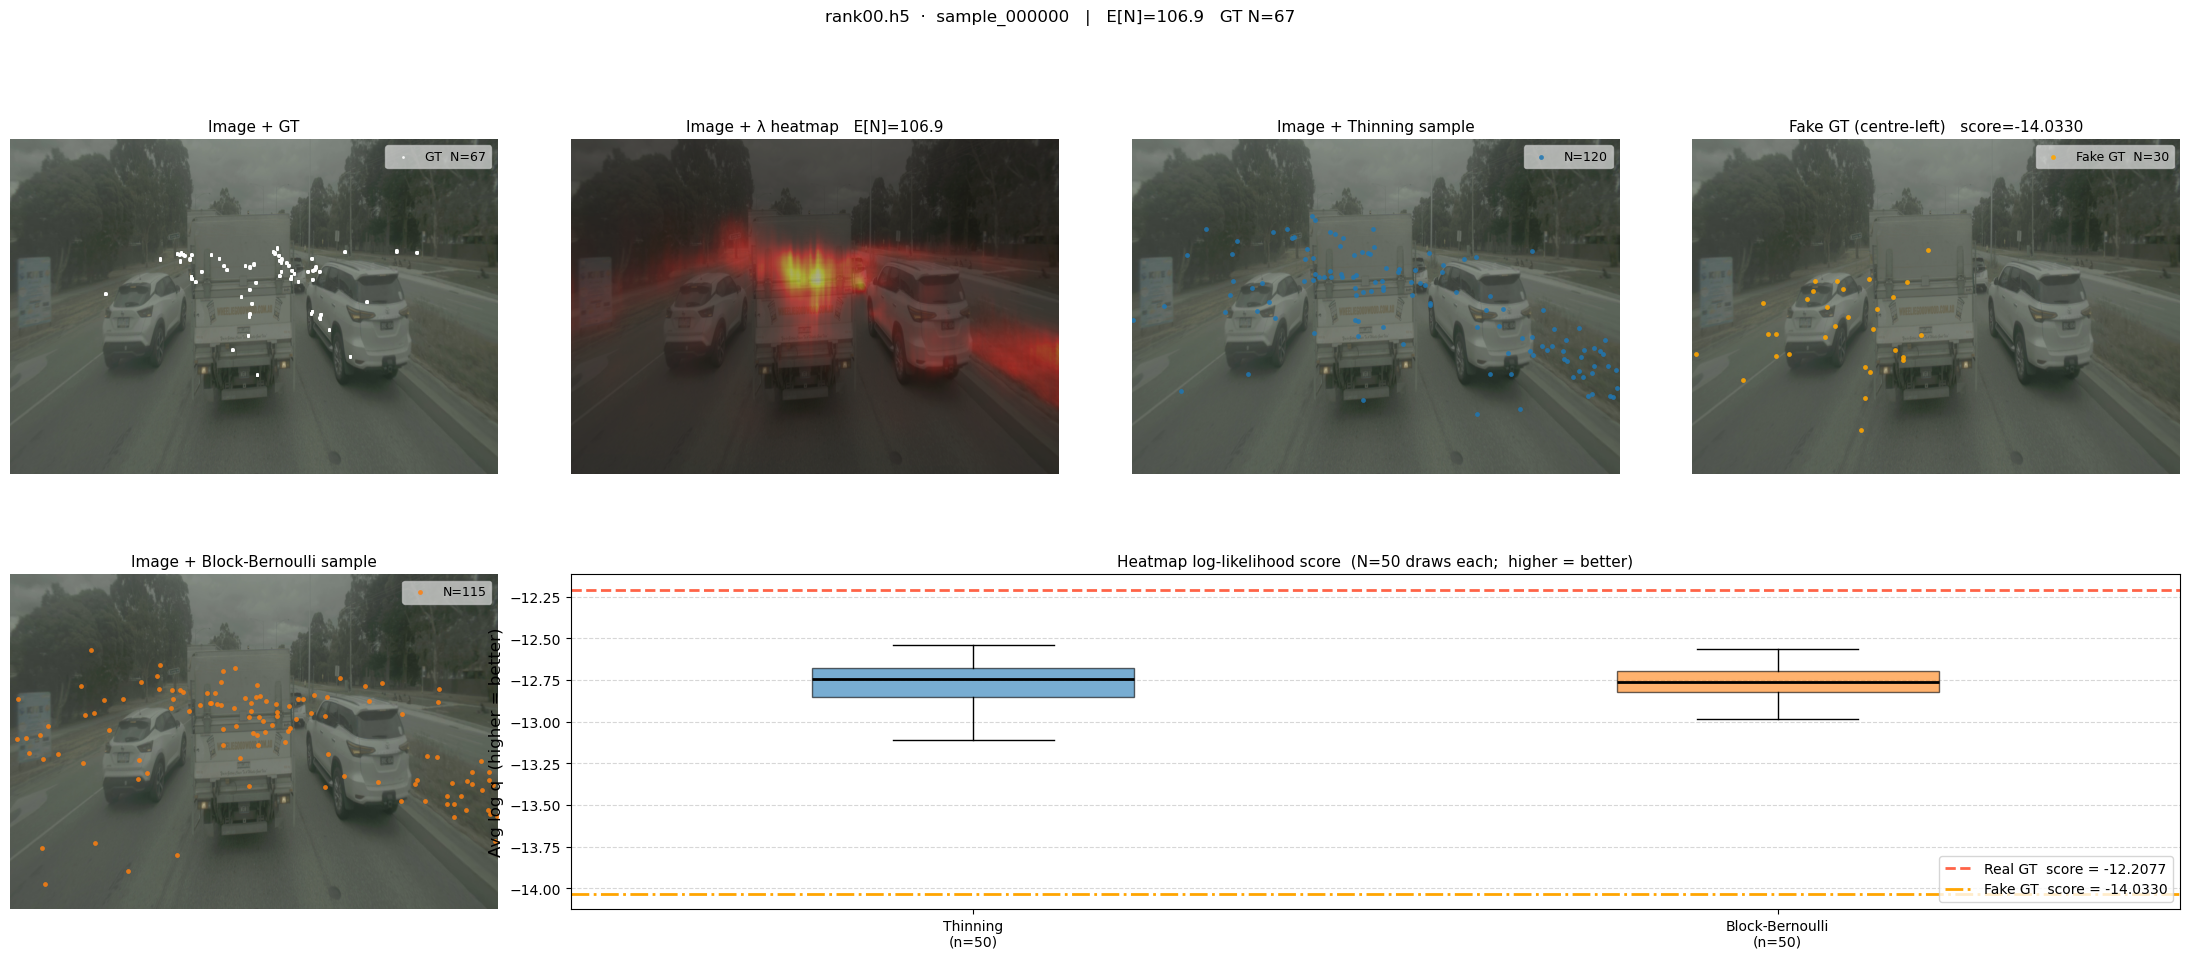

/tmp/ipykernel_23432/1276041259.py:130: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax_box.boxplot(_bp_data, labels=_bp_labels, patch_artist=True,


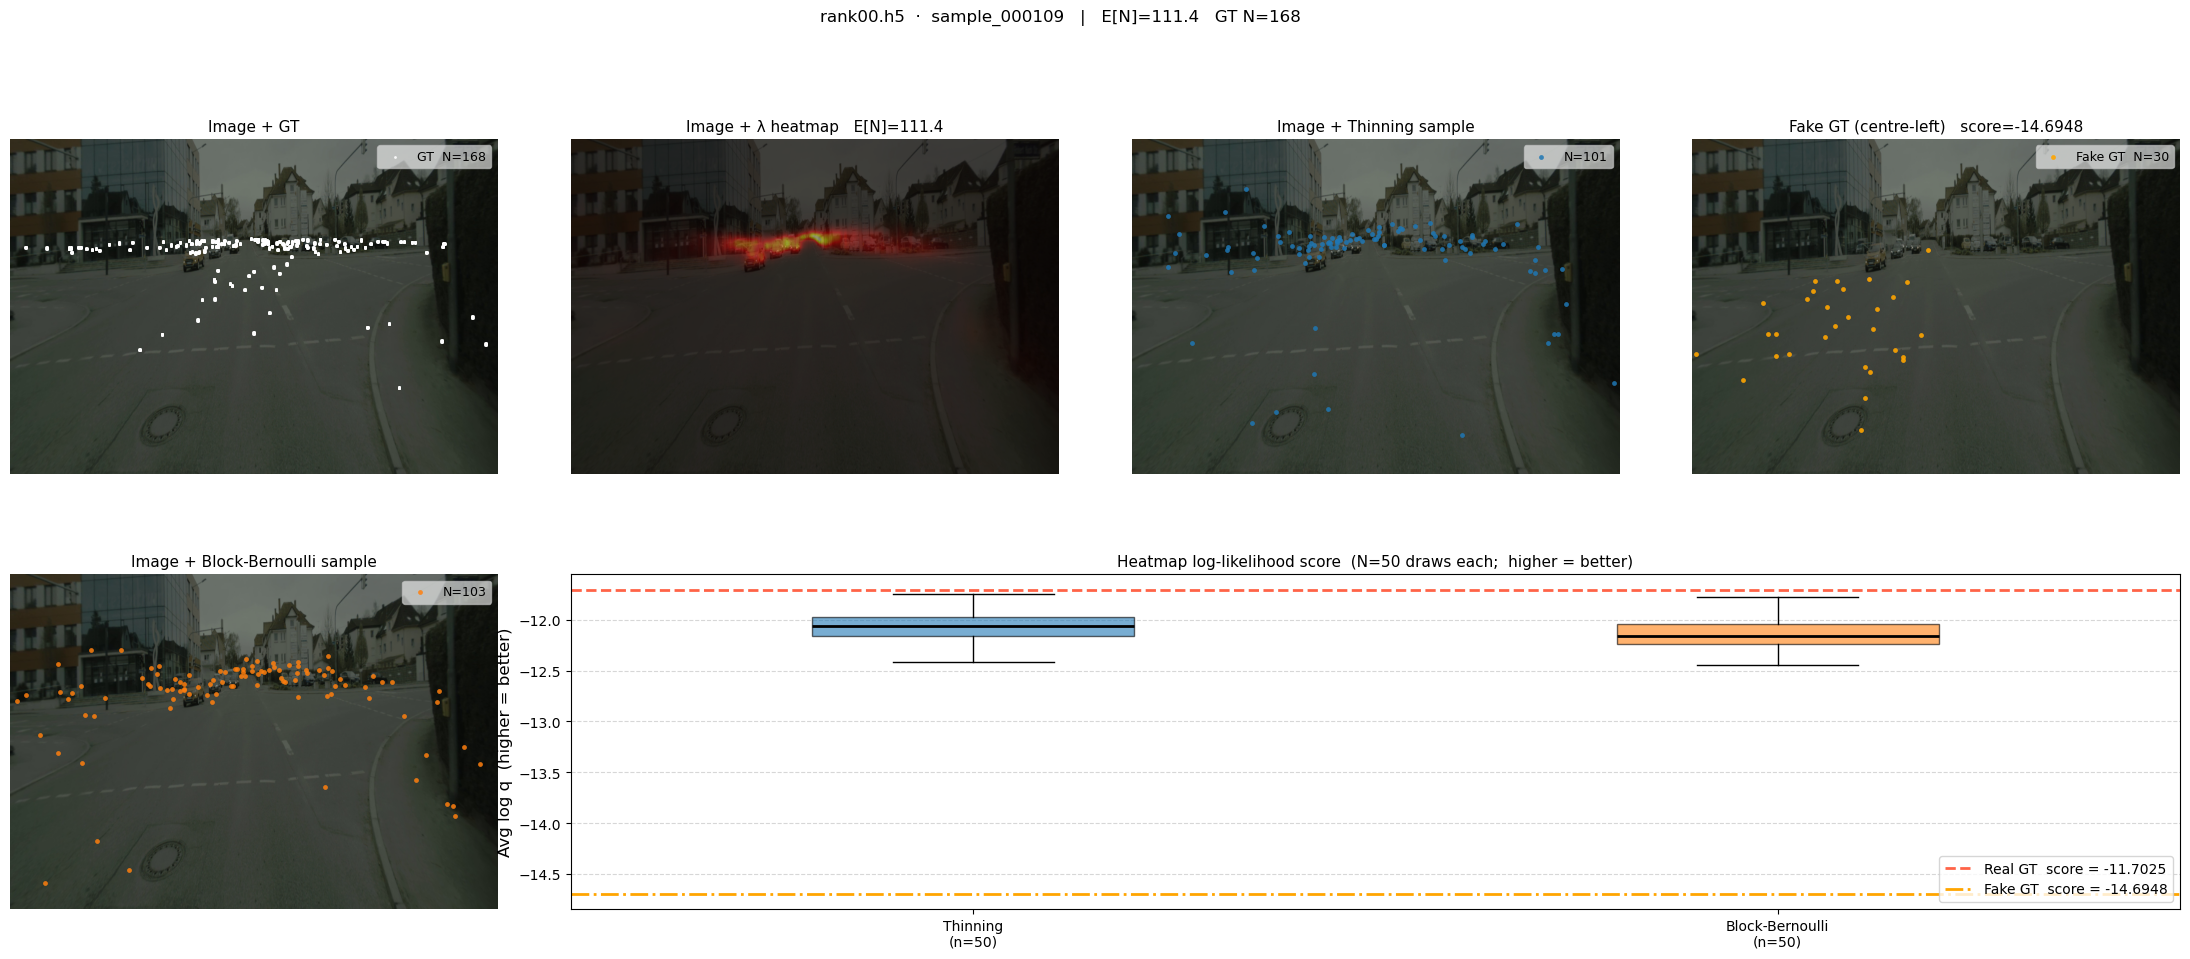

In [ ]:

assert selected_samples, "No samples selected – browse and add at least one above."

from matplotlib.gridspec import GridSpec

# ── Fake-GT parameters ────────────────────────────────────────────────────────
# A Gaussian cluster of N_GT points placed at a fixed relative position.
# Adjust the centre/spread fractions to place it in a region unlikely to
# overlap with the true GT cluster for a visual worst-case comparison.
FAKE_CX_FRAC = 0.25   # horizontal centre of fake cluster  (fraction of W)
FAKE_CY_FRAC = 0.60   # vertical   centre of fake cluster  (fraction of H)
FAKE_SX_FRAC = 0.10   # horizontal spread  (fraction of W)
FAKE_SY_FRAC = 0.10   # vertical   spread  (fraction of H)

_frng = np.random.default_rng(42)   # fixed seed for reproducibility

for _idx, (_h5_file, _key) in enumerate(selected_samples):

    # ── Load sample ──────────────────────────────────────────────────────────
    _h5_path = next(
        p for (p, k) in all_samples
        if os.path.basename(p) == _h5_file and k == _key
    )
    _s           = load_h5_sample(_h5_path, _key)
    _img         = _s["img"]
    _pred_lambda = _s["pred_lambda"].astype(np.float64)
    _gt_support  = _s["gt_support"].astype(np.float64)
    _ppp         = _s["ppp"]
    H_img, W_img = _pred_lambda.shape

    N_GT   = int(_gt_support.sum())
    Lambda = float(_pred_lambda.sum())

    # ── Real GT heatmaps (normalised to sum = N_GT) ──────────────────────────
    _h_pred = _pred_lambda * (N_GT / Lambda) if Lambda > 0 else _pred_lambda.copy()
    _h_GT   = build_pseudo_gt_heatmap(_gt_support, sigma=SIGMA_PX)

    _gt_mask = _gt_support > 0.5
    _gt_ys, _gt_xs = np.where(_gt_mask)

    _log_pred_map   = np.where(_gt_mask, np.log(np.clip(_h_pred, EPS, None)), np.nan)
    _log_pseudo_map = np.where(_gt_mask, np.log(np.clip(_h_GT,   EPS, None)), np.nan)

    _m_real = gaussian_mmd_score(_gt_support, _pred_lambda, sigma=SIGMA_PX)

    # ── Fake GT: Gaussian cluster with same N_GT ──────────────────────────────
    _N_fake = max(N_GT, 1)
    _cx = W_img * FAKE_CX_FRAC;  _cy = H_img * FAKE_CY_FRAC
    _sx = W_img * FAKE_SX_FRAC;  _sy = H_img * FAKE_SY_FRAC
    _fake_xs = np.clip(_frng.normal(_cx, _sx, size=_N_fake), 0, W_img - 1).astype(int)
    _fake_ys = np.clip(_frng.normal(_cy, _sy, size=_N_fake), 0, H_img - 1).astype(int)

    _fake_support = np.zeros((H_img, W_img), dtype=np.float64)
    _fake_support[_fake_ys, _fake_xs] = 1.0   # may have collisions → fewer unique pixels

    _h_fake_GT = build_pseudo_gt_heatmap(_fake_support, sigma=SIGMA_PX)

    _fake_mask = _fake_support > 0.5
    _fake_ys_u, _fake_xs_u = np.where(_fake_mask)
    N_fake_unique = int(_fake_support.sum())

    # log h_pred at fake GT locations  (to see if pred concentrates there)
    _h_pred_fake = _pred_lambda * (N_fake_unique / Lambda) if Lambda > 0 else _pred_lambda.copy()
    _log_pred_at_fake  = np.where(_fake_mask, np.log(np.clip(_h_pred_fake, EPS, None)), np.nan)
    _log_pseudo_at_fake= np.where(_fake_mask, np.log(np.clip(_h_fake_GT,   EPS, None)), np.nan)

    _m_fake = gaussian_mmd_score(_fake_support, _pred_lambda, sigma=SIGMA_PX)

    # ── Shared colour limits (real + fake log maps on common scale) ───────────
    _all_log_vals = [
        _log_pred_map,   _log_pseudo_map,
        _log_pred_at_fake, _log_pseudo_at_fake,
    ]
    _vmin = min(np.nanmin(v) for v in _all_log_vals)
    _vmax = max(np.nanmax(v) for v in _all_log_vals)

    # ── Figure layout: 3 × 3 ─────────────────────────────────────────────────
    _ext    = [0, W_img, H_img, 0]
    _struct = np.ones((2 * GT_DILATION_RADIUS + 1, 2 * GT_DILATION_RADIUS + 1), bool)

    fig = plt.figure(figsize=(24, 14))
    gs  = GridSpec(3, 3, figure=fig, hspace=0.40, wspace=0.20)

    ax_img       = fig.add_subplot(gs[0, 0])   # row 0: Image + real GT
    ax_hpred     = fig.add_subplot(gs[0, 1])   # row 0: h_pred (real scale)
    ax_hgt       = fig.add_subplot(gs[0, 2])   # row 0: pseudo-GT heatmap

    ax_lpred     = fig.add_subplot(gs[1, 0])   # row 1: log h_pred @ real GT
    ax_lpseudo   = fig.add_subplot(gs[1, 1])   # row 1: log h_GT @ real GT
    ax_bar       = fig.add_subplot(gs[1, 2])   # row 1: score comparison bar

    ax_fake_img  = fig.add_subplot(gs[2, 0])   # row 2: Image + fake GT
    ax_hfake     = fig.add_subplot(gs[2, 1])   # row 2: pseudo-fake heatmap
    ax_lpred_fk  = fig.add_subplot(gs[2, 2])   # row 2: log h_pred @ fake GT

    # ── Row 0, Panel 0: Image + real GT ──────────────────────────────────────
    ax_img.imshow(_img, aspect="auto", extent=_ext)
    if _gt_ys.size > 0:
        ax_img.scatter(_gt_xs, _gt_ys, s=4, c="white", linewidths=0, alpha=0.9,
                       label=f"Real GT  N={N_GT}")
    ax_img.legend(loc="upper right", fontsize=9, framealpha=0.6)
    ax_img.axis("off")
    ax_img.set_title("Image + Real GT", fontsize=11)

    # ── Row 0, Panel 1: h_pred (normalised to N_GT) ──────────────────────────
    im1 = ax_hpred.imshow(_h_pred, cmap="hot", aspect="auto")
    ax_hpred.axis("off")
    ax_hpred.set_title(
        r"$h_\mathrm{pred}$ = λ · N_GT / Λ"
        f"\nE[N]={_ppp['expected_count']:.1f}   N_GT={N_GT}",
        fontsize=10,
    )
    plt.colorbar(im1, ax=ax_hpred, fraction=0.046, pad=0.04)

    # ── Row 0, Panel 2: pseudo-GT heatmap ────────────────────────────────────
    im2 = ax_hgt.imshow(_h_GT, cmap="hot", aspect="auto")
    ax_hgt.axis("off")
    ax_hgt.set_title(
        r"$h_\mathrm{GT}$ Gaussian bumps  σ=" + f"{SIGMA_PX} px"
        f"\nsum={_h_GT.sum():.1f}",
        fontsize=10,
    )
    plt.colorbar(im2, ax=ax_hgt, fraction=0.046, pad=0.04)

    # ── Row 1, Panel 0: log h_pred at real GT pixels ─────────────────────────
    im3 = ax_lpred.imshow(_log_pred_map, cmap="viridis", aspect="auto",
                          vmin=_vmin, vmax=_vmax)
    ax_lpred.axis("off")
    ax_lpred.set_title(
        r"$\log\,h_\mathrm{pred}$ @ real GT pixels"
        f"\nscore_pred = {_m_real['score_pred']:.4f}",
        fontsize=10,
    )
    plt.colorbar(im3, ax=ax_lpred, fraction=0.046, pad=0.04)

    # ── Row 1, Panel 1: log h_GT at real GT pixels ───────────────────────────
    im4 = ax_lpseudo.imshow(_log_pseudo_map, cmap="viridis", aspect="auto",
                            vmin=_vmin, vmax=_vmax)
    ax_lpseudo.axis("off")
    ax_lpseudo.set_title(
        r"$\log\,h_\mathrm{GT}$ @ real GT pixels  (reference)"
        f"\nscore_pseudo = {_m_real['score_pseudo']:.4f}",
        fontsize=10,
    )
    plt.colorbar(im4, ax=ax_lpseudo, fraction=0.046, pad=0.04)

    # ── Row 1, Panel 2: Score comparison bar chart ───────────────────────────
    _blabels = [
        "score_pred\n(real GT)",
        "score_pseudo\n(real GT ref)",
        "MMD\n(real GT)",
        "score_pred\n(fake GT)",
        "score_pseudo\n(fake GT ref)",
        "MMD\n(fake GT)",
    ]
    _bvals  = [
        _m_real["score_pred"],  _m_real["score_pseudo"],  _m_real["mmd_score"],
        _m_fake["score_pred"],  _m_fake["score_pseudo"],  _m_fake["mmd_score"],
    ]
    _bcolors = [
        "steelblue", "seagreen",
        "mediumorchid" if _m_real["mmd_score"] >= 0 else "tomato",
        "cornflowerblue", "mediumseagreen",
        "mediumorchid" if _m_fake["mmd_score"] >= 0 else "tomato",
    ]
    _x_pos = np.arange(len(_blabels))
    bars = ax_bar.bar(_x_pos, _bvals, color=_bcolors, alpha=0.75,
                      edgecolor="k", linewidth=0.8)
    ax_bar.set_xticks(_x_pos)
    ax_bar.set_xticklabels(_blabels, fontsize=7)
    _off = 0.003 * max(abs(v) for v in _bvals if not np.isnan(v)) + 0.001
    for b, v in zip(bars, _bvals):
        if np.isnan(v):
            continue
        ax_bar.text(b.get_x() + b.get_width() / 2,
                    v + (_off if v >= 0 else -_off * 3.5),
                    f"{v:.3f}", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=7)
    ax_bar.axvline(2.5, color="grey", linestyle="--", linewidth=1.0)  # separator
    ax_bar.axhline(0, color="grey", linewidth=0.7)
    ax_bar.set_ylabel("Score  (higher = better)", fontsize=9)
    ax_bar.set_title(
        f"Score comparison  σ={SIGMA_PX} px\n"
        f"MMD real={_m_real['mmd_score']:+.4f}   MMD fake={_m_fake['mmd_score']:+.4f}",
        fontsize=10,
    )
    ax_bar.yaxis.grid(True, linestyle="--", alpha=0.45)
    ax_bar.set_axisbelow(True)
    # shade real vs fake regions
    ax_bar.axvspan(-0.5, 2.5, alpha=0.05, color="steelblue")
    ax_bar.axvspan(2.5,  5.5, alpha=0.05, color="orange")

    # ── Row 2, Panel 0: Image + fake GT ──────────────────────────────────────
    ax_fake_img.imshow(_img, aspect="auto", extent=_ext)
    if _fake_xs_u.size > 0:
        ax_fake_img.scatter(_fake_xs_u, _fake_ys_u, s=4, c="orange",
                            linewidths=0, alpha=0.9,
                            label=f"Fake GT  N≈{N_fake_unique}")
    ax_fake_img.legend(loc="upper right", fontsize=9, framealpha=0.6)
    ax_fake_img.axis("off")
    ax_fake_img.set_title(f"Image + Fake GT  (Gaussian cluster)", fontsize=11)

    # ── Row 2, Panel 1: Pseudo-fake heatmap ──────────────────────────────────
    im5 = ax_hfake.imshow(_h_fake_GT, cmap="hot", aspect="auto")
    ax_hfake.axis("off")
    ax_hfake.set_title(
        r"$h_\mathrm{fake}$ Gaussian bumps  σ=" + f"{SIGMA_PX} px"
        f"\nsum={_h_fake_GT.sum():.1f}",
        fontsize=10,
    )
    plt.colorbar(im5, ax=ax_hfake, fraction=0.046, pad=0.04)

    # ── Row 2, Panel 2: log h_pred at fake GT pixels ─────────────────────────
    im6 = ax_lpred_fk.imshow(_log_pred_at_fake, cmap="viridis", aspect="auto",
                              vmin=_vmin, vmax=_vmax)
    ax_lpred_fk.axis("off")
    ax_lpred_fk.set_title(
        r"$\log\,h_\mathrm{pred}$ @ fake GT pixels"
        f"\nscore_pred(fake) = {_m_fake['score_pred']:.4f}",
        fontsize=10,
    )
    plt.colorbar(im6, ax=ax_lpred_fk, fraction=0.046, pad=0.04)

    plt.suptitle(
        f"[{_idx + 1}/{len(selected_samples)}]  {_h5_file}  ·  {_key}"
        f"   |   E[N]={_ppp['expected_count']:.1f}   N_GT={N_GT}   σ={SIGMA_PX} px\n"
        f"Real MMD = {_m_real['mmd_score']:+.4f}   "
        f"Fake MMD = {_m_fake['mmd_score']:+.4f}   "
        f"Δ = {_m_real['mmd_score'] - _m_fake['mmd_score']:+.4f}",
        fontsize=12, y=1.01,
    )
    plt.show()


## Full-Dataset Gaussian-MMD Analysis

Runs over **every** sample in every model directory.

**Per sample $s$** with $N_s$ GT points and predicted intensity $\lambda_s(x)$:

$$h_\text{pred}(x) = \lambda(x)\cdot\frac{N_s}{\Lambda_s}, \qquad \Lambda_s = \sum_x \lambda_s(x)$$

$$h_\text{GT}(x) = \sum_{j\in\text{GT}} G_\sigma(x - x_j)\cdot\frac{N_s}{\sum_x \bigl(\sum_j G_\sigma(x-x_j)\bigr)}$$

At each GT location $x_i$:

$$\text{score\_pred}_s = \frac{1}{N_s}\sum_{i\in\text{GT}} \log h_\text{pred}(x_i)$$

$$\text{score\_pseudo}_s = \frac{1}{N_s}\sum_{i\in\text{GT}} \log h_\text{GT}(x_i) \quad\leftarrow\text{same-sample reference}$$

$$\text{MMD}_s = \text{score\_pred}_s - \text{score\_pseudo}_s$$

Model-level summary: $\bar{\text{MMD}} = \tfrac{1}{S}\sum_s \text{MMD}_s$.  Higher $\Rightarrow$ better alignment.

The pseudo-GT score $\text{score\_pseudo}_s$ provides a per-sample baseline that adapts to $N_s$ and $\sigma$, so the MMD difference is interpretable across images of varying density.



  Model: test_gen_data_meric_13600264  (100 samples, K=50 draws)
  10/100
  20/100
  30/100
  40/100
  50/100
  60/100
  70/100
  80/100
  90/100
  100/100

  Mean log-likelihood score  (higher = better)
  Method                    mean score      SD score
  --------------------------------------------------
  GT (real data)              -11.9310        0.9012
  Thinning (mean)             -12.4077        0.8726
  Block-Bernoulli             -12.4996        0.7922

  Empirical-null z-scores  (mean z ≈ 0, SD z ≈ 1  under null)
  Method                    mean z      SD z    p (bias)    p (disp)
  ----------------------------------------------------------------
  GT (real data)             5.380     5.187    2.18e-17     <1e-300  ***
  Thinning (LOO)            -0.000     0.004       0.544    >1-1e-15
  Block-Bernoulli           -0.745     0.752    2.22e-16       0.195  ***
  *** p < 0.05


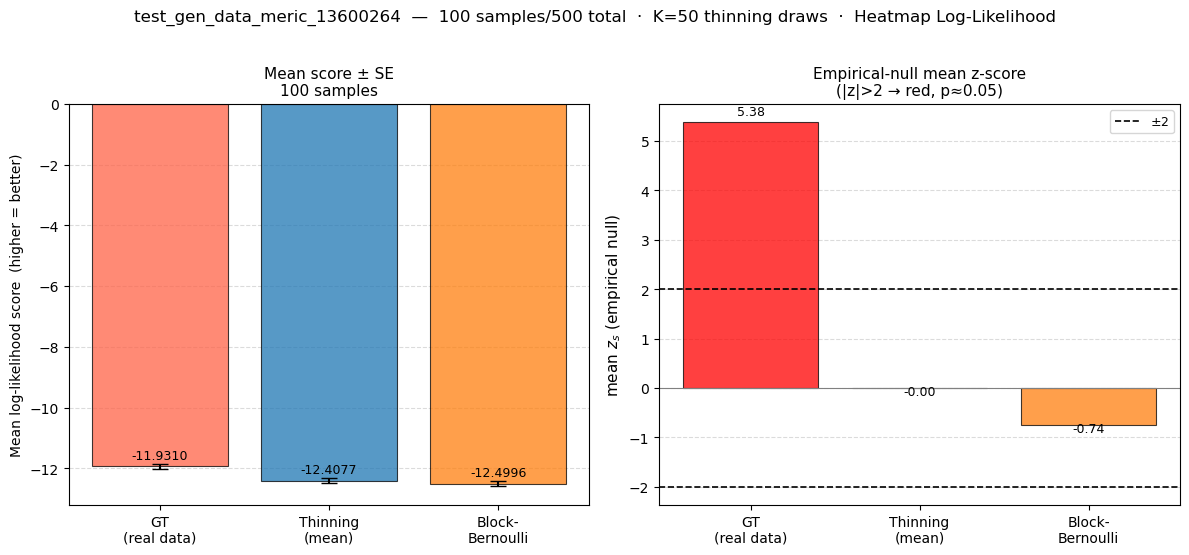


  Model: test_gen_data_meric_1500_13603608_LR_load_model40000  (100 samples, K=50 draws)
  10/100
  20/100
  30/100
  40/100
  50/100
  60/100
  70/100
  80/100
  90/100
  100/100

  Mean log-likelihood score  (higher = better)
  Method                    mean score      SD score
  --------------------------------------------------
  GT (real data)              -12.4630        1.0653
  Thinning (mean)             -12.4392        1.0579
  Block-Bernoulli             -12.4849        0.9949

  Empirical-null z-scores  (mean z ≈ 0, SD z ≈ 1  under null)
  Method                    mean z      SD z    p (bias)    p (disp)
  ----------------------------------------------------------------
  GT (real data)            -0.211     2.370       0.378    3.06e-66
  Thinning (LOO)             0.000     0.004       0.701    >1-1e-15
  Block-Bernoulli           -0.256     0.450    1.54e-07    1.00e+00  ***
  *** p < 0.05


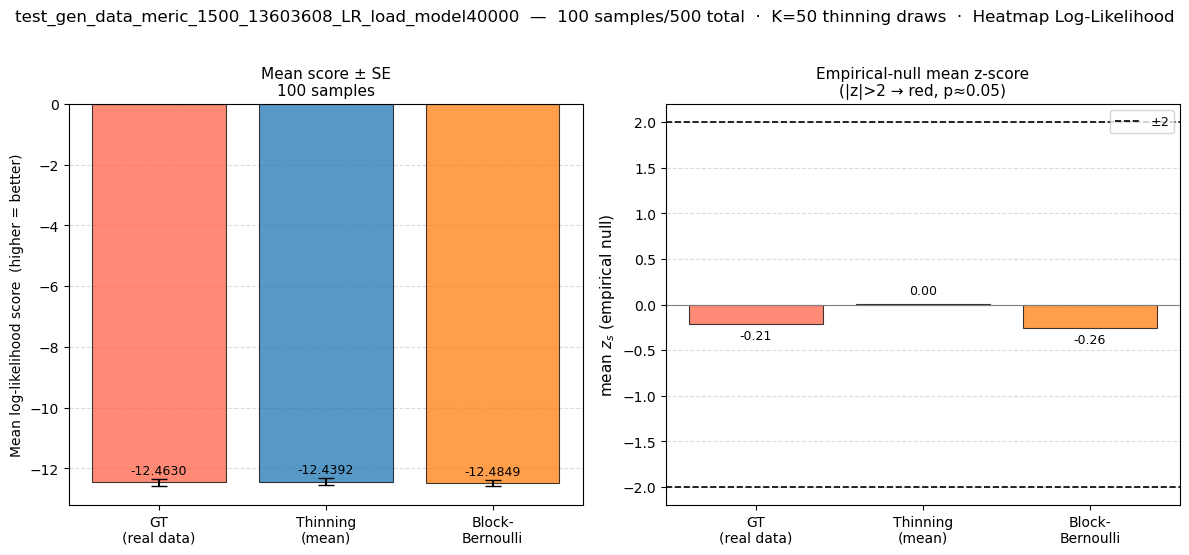


  Model: test_gen_data_meric_1500_13606074  (100 samples, K=50 draws)
  10/100
  20/100
  30/100
  40/100
  50/100
  60/100
  70/100
  80/100
  90/100
  100/100

  Mean log-likelihood score  (higher = better)
  Method                    mean score      SD score
  --------------------------------------------------
  GT (real data)              -13.9524        0.4981
  Thinning (mean)             -13.3657        0.3807
  Block-Bernoulli             -13.3620        0.3856

  Empirical-null z-scores  (mean z ≈ 0, SD z ≈ 1  under null)
  Method                    mean z      SD z    p (bias)    p (disp)
  ----------------------------------------------------------------
  GT (real data)            -6.901    10.847    7.21e-09     <1e-300  ***
  Thinning (LOO)            -0.002     0.006    4.52e-05    >1-1e-15  ***
  Block-Bernoulli            0.048     0.164       0.005    >1-1e-15  ***
  *** p < 0.05


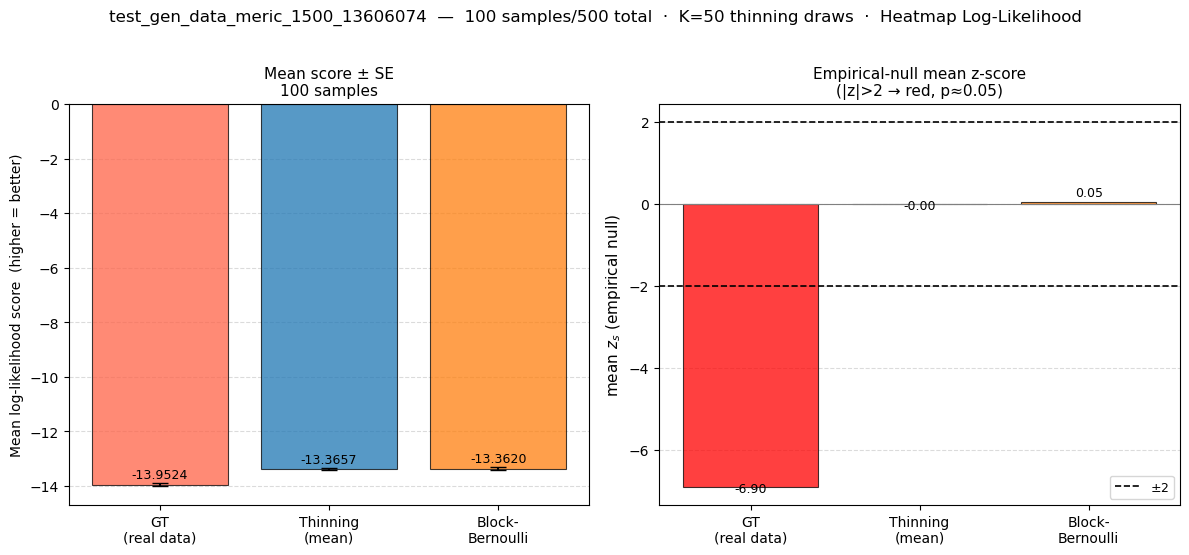

In [ ]:

from scipy import stats as scipy_stats

N_SAMPLES_EVAL = 100    # max samples per model  (None = all)


def run_gaussian_mmd_analysis(model_name: str, h5_dir: str, sigma: float = SIGMA_PX):
    """
    Full-dataset Gaussian-MMD analysis for one model directory.

    For every sample s:
        gaussian_mmd_score(gt_support_s, pred_lambda_s, sigma=sigma)
          → mmd_s, score_pred_s, score_pseudo_s

    Summary statistics and a 2-panel figure are produced:
      Panel 1 – mean score_pred  vs  mean score_pseudo  (bar ± SE)
      Panel 2 – distribution of per-sample MMD scores   (histogram + KDE)
    """
    _h5_files = sorted(glob.glob(os.path.join(h5_dir, "rank*.h5")))
    assert _h5_files, f"No rank*.h5 files found in {h5_dir}"

    _all  = list_h5_samples(_h5_files)
    _eval = _all if N_SAMPLES_EVAL is None else _all[:N_SAMPLES_EVAL]
    total = len(_eval)

    print(f"\n{'='*72}")
    print(f"  Model : {model_name}")
    print(f"  σ     : {sigma} px  |  samples: {total}  (of {len(_all)} total)")
    print(f"{'='*72}")

    mmd_list   = []
    pred_list  = []
    pseudo_list= []

    for idx, (_h5_path, _key) in enumerate(_eval):
        if (idx + 1) % max(1, total // 10) == 0 or idx == total - 1:
            print(f"  {idx + 1}/{total}", flush=True)

        _s = load_h5_sample(_h5_path, _key)
        m  = gaussian_mmd_score(_s["gt_support"], _s["pred_lambda"], sigma=sigma)

        if not np.isnan(m["mmd_score"]):
            mmd_list.append(m["mmd_score"])
            pred_list.append(m["score_pred"])
            pseudo_list.append(m["score_pseudo"])

    mmd_arr   = np.array(mmd_list)
    pred_arr  = np.array(pred_list)
    pseudo_arr= np.array(pseudo_list)

    # ── One-sample t-test: is mean(MMD) ≠ 0? ────────────────────────────────
    t_stat, p_val = scipy_stats.ttest_1samp(mmd_arr, popmean=0.0)
    ci_lo, ci_hi  = scipy_stats.t.interval(
        0.95, df=len(mmd_arr) - 1,
        loc=mmd_arr.mean(), scale=scipy_stats.sem(mmd_arr)
    )

    print(f"\n  Scores  (higher = better):")
    print(f"  {'Metric':<24}  {'mean':>10}  {'std':>10}  {'median':>10}")
    print(f"  {'-'*56}")
    for nm, arr in [
        ("score_pred   (λ norm)", pred_arr),
        ("score_pseudo (GT ref)", pseudo_arr),
        ("MMD = pred − pseudo",   mmd_arr),
    ]:
        print(f"  {nm:<24}  {arr.mean():>10.4f}  {arr.std():>10.4f}  {np.median(arr):>10.4f}")

    print(f"\n  One-sample t-test  H0: mean(MMD) = 0")
    print(f"  t = {t_stat:.3f}   p = {p_val:.4g}   95% CI: [{ci_lo:.4f}, {ci_hi:.4f}]")
    sig = "  *** significant" if p_val < 0.05 else "  (not significant at 5%)"
    print(f"  {sig}")

    # ── Figure ────────────────────────────────────────────────────────────────
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    _colors = ["steelblue", "seagreen"]

    # Panel 1: mean score_pred vs mean score_pseudo ± SE
    vals  = [pred_arr.mean(), pseudo_arr.mean()]
    sems  = [scipy_stats.sem(pred_arr), scipy_stats.sem(pseudo_arr)]
    bars1 = ax1.bar(
        ["score_pred\n(predicted)", "score_pseudo\n(GT reference)"],
        vals, color=_colors, alpha=0.75, edgecolor="k", linewidth=0.8,
        yerr=sems, capsize=6, error_kw=dict(ecolor="black", elinewidth=1.5),
    )
    for b, v, s in zip(bars1, vals, sems):
        ax1.text(b.get_x() + b.get_width() / 2, v + s + abs(v) * 0.004,
                 f"{v:.4f}", ha="center", va="bottom", fontsize=9)
    ax1.set_ylabel("Mean log score  (higher = better)", fontsize=10)
    ax1.set_title(f"Mean scores ± SE\n{len(mmd_arr)} samples", fontsize=11)
    ax1.yaxis.grid(True, linestyle="--", alpha=0.45)
    ax1.set_axisbelow(True)

    # Panel 2: histogram of per-sample MMD scores
    ax2.hist(mmd_arr, bins=30, color="mediumorchid", alpha=0.70, edgecolor="white",
             linewidth=0.5, label="per-sample MMD")
    ax2.axvline(mmd_arr.mean(), color="black", linewidth=1.8,
                label=f"mean = {mmd_arr.mean():.4f}")
    ax2.axvline(0.0, color="grey", linestyle="--", linewidth=1.2, label="0 (reference)")
    if p_val < 0.05:
        ax2.axvspan(ci_lo, ci_hi, alpha=0.15, color="red", label="95% CI (sign.)")
    ax2.set_xlabel("MMD score = score_pred − score_pseudo", fontsize=10)
    ax2.set_ylabel("Count", fontsize=10)
    ax2.set_title(
        f"MMD score distribution  (σ={sigma} px)\n"
        f"mean={mmd_arr.mean():.4f}  std={mmd_arr.std():.4f}  p={p_val:.4g}",
        fontsize=11,
    )
    ax2.legend(fontsize=9)
    ax2.yaxis.grid(True, linestyle="--", alpha=0.45)
    ax2.set_axisbelow(True)

    plt.suptitle(
        f"{model_name}  —  Gaussian-MMD  (σ={sigma} px)  ·  {len(mmd_arr)} samples",
        fontsize=12, y=1.02,
    )
    plt.tight_layout()
    return fig, dict(
        model=model_name, sigma=sigma,
        n=len(mmd_arr),
        mean_mmd=mmd_arr.mean(), std_mmd=mmd_arr.std(), median_mmd=np.median(mmd_arr),
        mean_score_pred=pred_arr.mean(), mean_score_pseudo=pseudo_arr.mean(),
        t_stat=t_stat, p_val=p_val, ci_lo=ci_lo, ci_hi=ci_hi,
    )


# ── Run for every registered model ────────────────────────────────────────────
_analysis_results = {}
for _model_name, _h5_dir in H5_DIRS.items():
    if not os.path.isdir(_h5_dir):
        print(f"SKIPPING {_model_name} — directory not found: {_h5_dir}")
        continue
    _fig, _res = run_gaussian_mmd_analysis(_model_name, _h5_dir, sigma=SIGMA_PX)
    _analysis_results[_model_name] = _res
    plt.show()


test_gen_data_meric_13600264  →  500 samples
  mean score = -11.8702   median = -11.7293   n = 500
test_gen_data_meric_1500_13603608_LR_load_model40000  →  500 samples
  mean score = -12.3944   median = -12.0480   n = 500
test_gen_data_meric_1500_13606074  →  500 samples
  mean score = -14.0322   median = -13.7928   n = 500


/tmp/ipykernel_23432/137313956.py:42: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


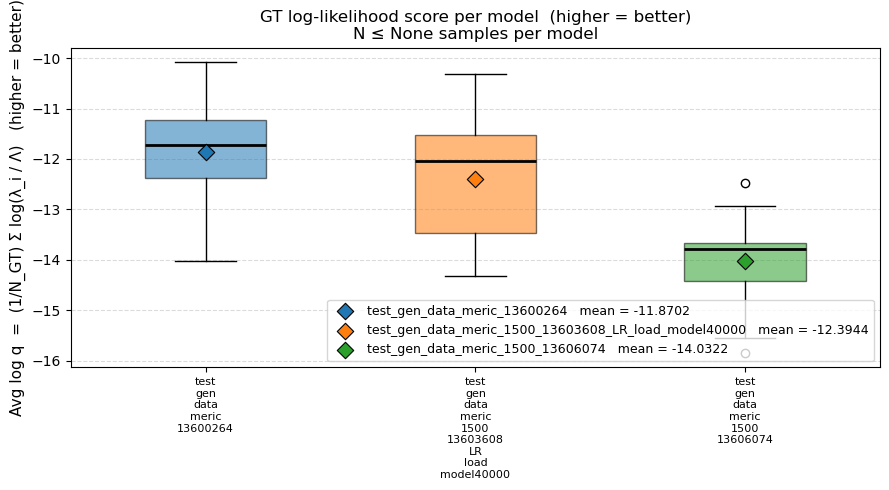

In [ ]:

# ── Gaussian-MMD model comparison ────────────────────────────────────────────
#
# Collects per-sample MMD scores for every registered model and produces
# a side-by-side comparison:
#   • Box plots of the full MMD-score distribution per model
#   • Mean score_pred vs score_pseudo per model (bar chart)
#
# Re-uses _analysis_results populated in the cell above if already run;
# otherwise re-computes from scratch.

SAMPLE_N = None   # max samples per model  (None = all)

mmd_per_model         = {}   # model → np.ndarray of per-sample MMD scores
score_pred_per_model  = {}
score_pseudo_per_model= {}

for _mname, _h5_dir in H5_DIRS.items():
    if not os.path.isdir(_h5_dir):
        print(f"SKIPPING {_mname} — not found")
        continue

    _h5_files = sorted(glob.glob(os.path.join(_h5_dir, "rank*.h5")))
    _all_s    = list_h5_samples(_h5_files)
    _eval_s   = _all_s if SAMPLE_N is None else _all_s[:SAMPLE_N]
    print(f"{_mname}  →  {len(_eval_s)} samples", flush=True)

    _mmds, _preds, _pseudos = [], [], []
    for _h5_path, _key in _eval_s:
        _s = load_h5_sample(_h5_path, _key)
        m  = gaussian_mmd_score(_s["gt_support"], _s["pred_lambda"], sigma=SIGMA_PX)
        if not np.isnan(m["mmd_score"]):
            _mmds.append(m["mmd_score"])
            _preds.append(m["score_pred"])
            _pseudos.append(m["score_pseudo"])

    mmd_per_model[_mname]          = np.array(_mmds)
    score_pred_per_model[_mname]   = np.array(_preds)
    score_pseudo_per_model[_mname] = np.array(_pseudos)

    arr = mmd_per_model[_mname]
    print(f"  MMD  mean={arr.mean():.4f}  median={np.median(arr):.4f}"
          f"  std={arr.std():.4f}  n={len(arr)}")

# ── Figure: 2 panels ──────────────────────────────────────────────────────────
_mnames = list(mmd_per_model.keys())
if not _mnames:
    print("No models available for comparison.")
else:
    _colors = [plt.cm.tab10.colors[i % 10] for i in range(len(_mnames))]
    _short  = [m.replace("_", "\n") for m in _mnames]

    fig, (ax_box, ax_bar) = plt.subplots(1, 2, figsize=(max(8, 4 * len(_mnames)), 5.5))

    # Panel 1: box plot of MMD score distribution
    _bp_vals = [mmd_per_model[m] for m in _mnames]
    bp = ax_box.boxplot(_bp_vals, labels=_short, patch_artist=True,
                        widths=0.45, medianprops=dict(color="black", linewidth=2))
    for patch, color in zip(bp["boxes"], _colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.55)
    for i, (vals, color) in enumerate(zip(_bp_vals, _colors), start=1):
        ax_box.scatter(i, vals.mean(), marker="D", s=70, color=color,
                       edgecolors="black", linewidths=0.8, zorder=5)
    ax_box.axhline(0.0, color="grey", linestyle="--", linewidth=1.2, label="0 (reference)")
    ax_box.set_ylabel("Gaussian-MMD score\n(pred − pseudo, higher = better)", fontsize=10)
    ax_box.set_title(f"MMD score distribution per model  (σ={SIGMA_PX} px)", fontsize=11)
    ax_box.legend(fontsize=9)
    ax_box.yaxis.grid(True, linestyle="--", alpha=0.45)
    ax_box.set_axisbelow(True)

    # Panel 2: mean score_pred vs score_pseudo per model (grouped bar)
    x_pos    = np.arange(len(_mnames))
    bar_w    = 0.30
    _pred_m  = [score_pred_per_model[m].mean()   for m in _mnames]
    _pseudo_m= [score_pseudo_per_model[m].mean() for m in _mnames]
    _pred_se = [scipy_stats.sem(score_pred_per_model[m])   for m in _mnames]
    _pseudo_se=[scipy_stats.sem(score_pseudo_per_model[m]) for m in _mnames]

    ax_bar.bar(x_pos - bar_w / 2, _pred_m,   width=bar_w, label="score_pred",
               color="steelblue",  alpha=0.75, edgecolor="k", linewidth=0.7,
               yerr=_pred_se,  capsize=5, error_kw=dict(ecolor="black", elinewidth=1.2))
    ax_bar.bar(x_pos + bar_w / 2, _pseudo_m, width=bar_w, label="score_pseudo (ref)",
               color="seagreen", alpha=0.75, edgecolor="k", linewidth=0.7,
               yerr=_pseudo_se, capsize=5, error_kw=dict(ecolor="black", elinewidth=1.2))
    ax_bar.set_xticks(x_pos)
    ax_bar.set_xticklabels(_short, fontsize=8)
    ax_bar.set_ylabel("Mean log score  (higher = better)", fontsize=10)
    ax_bar.set_title(
        f"Mean score_pred vs score_pseudo per model ± SE\n(σ={SIGMA_PX} px)",
        fontsize=11,
    )
    ax_bar.legend(fontsize=9)
    ax_bar.yaxis.grid(True, linestyle="--", alpha=0.45)
    ax_bar.set_axisbelow(True)

    plt.suptitle(
        f"Gaussian-MMD Model Comparison  (σ={SIGMA_PX} px)"
        f"{'  ·  N ≤ ' + str(SAMPLE_N) if SAMPLE_N else ''}",
        fontsize=13, y=1.02,
    )
    plt.tight_layout()
    plt.show()

    # ── Summary table ──────────────────────────────────────────────────────────
    print(f"\n{'Model':<55}  {'mean_MMD':>10}  {'std':>8}  {'n':>6}")
    print(f"  {'-'*80}")
    for mn in _mnames:
        arr = mmd_per_model[mn]
        print(f"  {mn:<53}  {arr.mean():>10.4f}  {arr.std():>8.4f}  {len(arr):>6}")
